In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
from scipy.stats.contingency import association

In [2]:
from scipy.stats import chi2_contingency

In [3]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [4]:
print(df.columns)
print(df.head())
print(df.info())

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')
   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False    

In [5]:
df_amazon = df.dropna(subset=['category', 'price', 'stars', 'isBestSeller']).copy()
df_amazon.shape

(2443651, 9)

In [6]:
crosstab_result = pd.crosstab(df_amazon['category'], df_amazon['isBestSeller'])
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [7]:
prop_top = (crosstab_result[True] / crosstab_result.sum(axis=1)).sort_values(ascending=False)
prop_top.head(15)

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
Professional Medical Supplies     0.027344
PC & Video Games                  0.025466
Bakeware                          0.025105
Material Handling Products        0.025000
Bedding Accessories               0.024390
dtype: float64

In [8]:
# Algunas categorías presentan mayor proporción de productos best-seller. Grocery es la categoría con mayor proporción, seguida de Smart Home Security & Lighting y Health & Personal Care, no son valores muy altos de proporción pero se diferencia con otras categorías que venden más. Esto puede indicar que un producto sea best-seller puede depender de la categoría.

In [9]:
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)
chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

In [10]:
# El test Chi2 muestra que los productos best-seller no son independientes de la categoría del producto(p value = 0.0), por lo que existe una relación significativa. Al tener un dataset muy grande, vamos a comprobar la relevancia de larelación usando Cramer's V.

In [11]:
association(crosstab_result, method="cramer")

0.1222829439760564

In [ ]:
# El valor de Cramer's V (0.122) indica que la fuerza de la relación que hay entre las variables de Categoria y Best Seller es débil. Significativa a nivel estadístico pero no en términos prácticos.

<Axes: xlabel='category'>

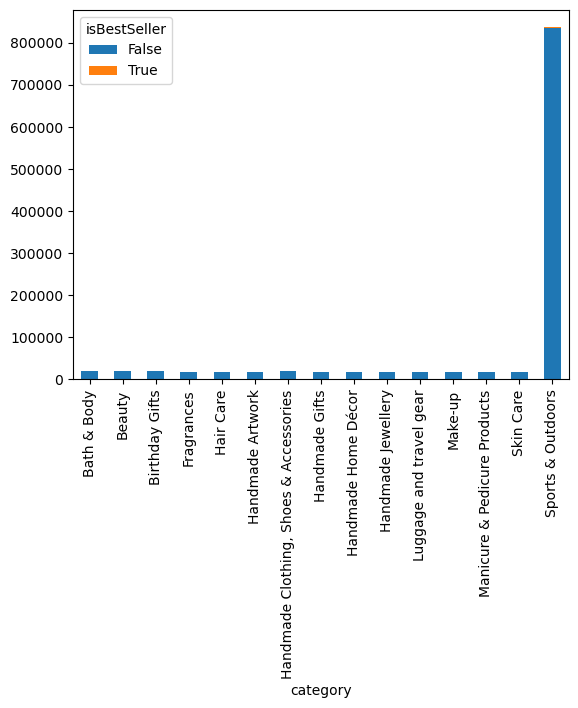

In [14]:
top15 = df_amazon['category'].value_counts().head(15).index
df_top15 = df_amazon[df_amazon['category'].isin(top15)]
crosstab_result_15 = pd.crosstab(df_top15['category'], df_top15['isBestSeller'])
crosstab_result_15.plot(kind='bar', stacked=True)

In [15]:
Q1 = df_amazon['price'].quantile(0.25)
Q3 = df_amazon['price'].quantile(0.75)
IQR = Q3 - Q1

below = Q1 - 1.5 * IQR
above = Q3 + 1.5 * IQR

df_amazon_price = df_amazon[(df_amazon['price'] > below) & (df_amazon['price'] < above)].copy()

df_amazon.shape, df_amazon_price.shape

((2443651, 9), (2115963, 9))

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 [Text(0, 0, 'Handmade Home & Kitchen Products'),
  Text(1, 0, 'Sports & Outdoors'),
  Text(2, 0, 'Handmade Gifts'),
  Text(3, 0, 'Fragrances'),
  Text(4, 0, 'Skin Care'),
  Text(5, 0, 'Birthday Gifts'),
  Text(6, 0, 'Handmade Kitchen & Dining'),
  Text(7, 0, 'Bath & Body'),
  Text(8, 0, 'Manicure & Pedicure Products'),
  Text(9, 0, 'Beauty'),
  Text(10, 0, 'Handmade Artwork'),
  Text(11, 0, 'Make-up'),
  Text(12, 0, 'Baby'),
  Text(13, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(14, 0, 'Handmade Home Décor'),
  Text(15, 0, 'Men'),
  Text(16, 0, 'Luggage and travel gear'),
  Text(17, 0, 'Handmade Jewellery'),
  Text(18, 0, 'Women'),
  Text(19, 0, 'Hair Care')])

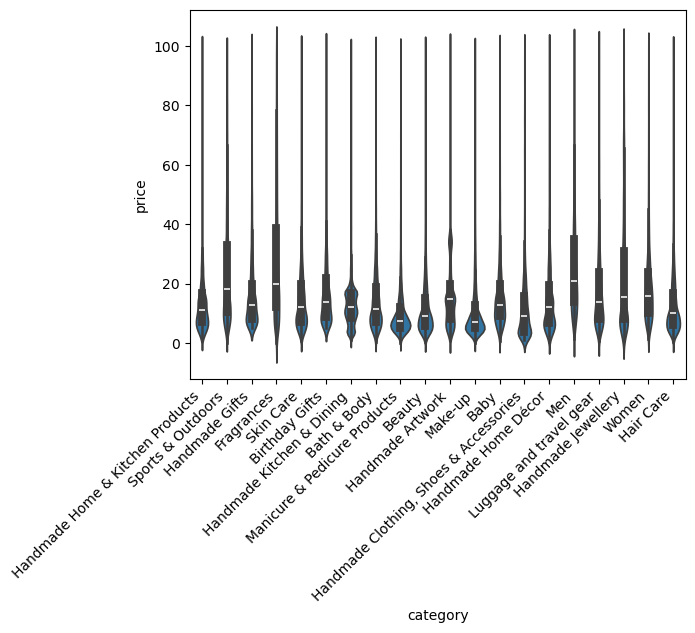

In [23]:
top20 = df_amazon_price['category'].value_counts().head(20).index
df_top20 = df_amazon_price[df_amazon_price['category'].isin(top20)]

sns.violinplot(data=df_top20, x='category', y='price')
plt.xticks(rotation=45, ha='right')

In [26]:
df_amazon_price.groupby('category')['price'].median().sort_values(ascending=False).head()

category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64

In [ ]:
# La categoría "Desktop PCs" tiene la mediana de precio más alta.

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Birthday Gifts'),
  Text(2, 0, 'Handmade Gifts'),
  Text(3, 0, 'Skin Care'),
  Text(4, 0, 'Bath & Body'),
  Text(5, 0, 'Hair Care'),
  Text(6, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(7, 0, 'Beauty'),
  Text(8, 0, 'Make-up'),
  Text(9, 0, 'Manicure & Pedicure Products')])

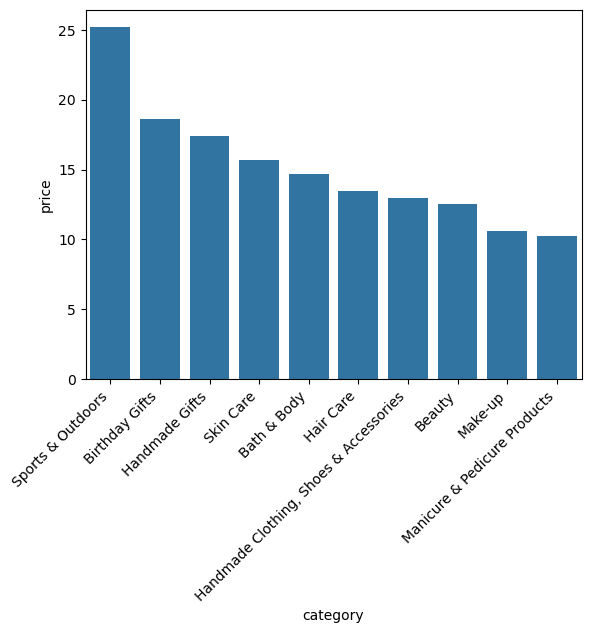

In [30]:
top10 = df_amazon_price['category'].value_counts().head(10).index

avg_price_top10 = (df_amazon_price[df_amazon_price['category'].isin(top10)].groupby('category')['price'].mean().sort_values(ascending=False))
avg_price_top10_df = avg_price_top10.reset_index()
sns.barplot(data=avg_price_top10_df, x='category', y='price')
plt.xticks(rotation=45, ha='right')

In [31]:
mean_price_by_cat = (df_amazon_price.groupby('category')['price'].mean().sort_values(ascending=False))
mean_price_by_cat.head()

category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64

In [ ]:
# La categoría que presenta la media de precio más alta es "Motherboards"(sin filtrar por categorías top)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Handmade Gifts'),
  Text(2, 0, 'Skin Care'),
  Text(3, 0, 'Birthday Gifts'),
  Text(4, 0, 'Bath & Body'),
  Text(5, 0, 'Manicure & Pedicure Products'),
  Text(6, 0, 'Beauty'),
  Text(7, 0, 'Make-up'),
  Text(8, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(9, 0, 'Hair Care')])

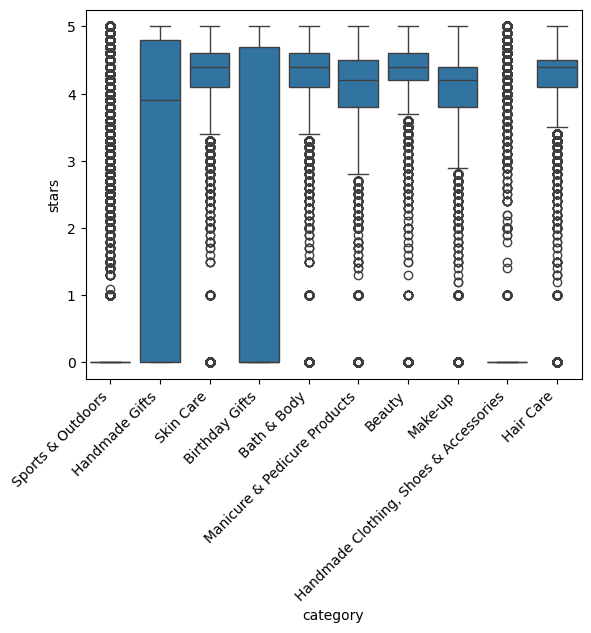

In [33]:
top10_cat_rating = df_amazon_price['category'].value_counts().head(10).index
top10_cat_rating_df = df_amazon_price[df_amazon_price['category'].isin(top10_cat_rating)].copy()

sns.boxplot(data=top10_cat_rating_df, x='category', y='stars')
plt.xticks(rotation=45, ha='right')

In [34]:
median_rating_by_cat = (df_amazon_price.groupby('category')['stars'].mean().sort_values(ascending=False))
median_rating_by_cat.head()

category
Luxury Food & Drink       4.544140
Grocery                   4.469414
Laptop Accessories        4.449600
Health & Personal Care    4.439549
Arts & Crafts             4.432942
Name: stars, dtype: float64

In [35]:
# La categoría sin filtrar que recibe la mediana más alta en rating es Luxury Food & Drink. 

In [36]:
correlation = df_amazon_price['price'].corr(df_amazon_price['stars'])
correlation

np.float64(-0.0776729987818137)

In [ ]:
# El valor -0.078 indica que hay una relación negativa muy débil, casi nula. En términos prácticos, no existe una relación lineal relevante entre la valoración y el precio.

<Axes: xlabel='stars', ylabel='price'>

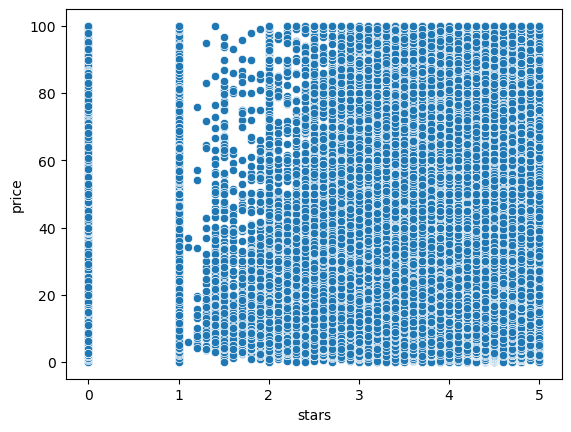

In [37]:
sns.scatterplot(data=df_amazon_price, x='stars', y='price')

In [ ]:
# El diagrama de dispersión muestra una alta dispersión de precios para todo el rango de rating de los productos. Como hemos visto antes, no se observa una tendencia que indique que los precios más altos tengan valoraciones más altas, o viceversa. Se confirma de nuevo que no existe una relación fuerte entre valoración y precio en este caso.

In [38]:
df_numeric = df_amazon_price[['price', 'stars', 'reviews', 'boughtInLastMonth']]
correlation_matrix = df_numeric.corr()
correlation_matrix

,price,stars,reviews,boughtInLastMonth
price,1.000000,-0.077673,-0.008498,-0.059051
stars,-0.077673,1.000000,0.083920,0.113994
reviews,-0.008498,0.083920,1.000000,0.105624
boughtInLastMonth,-0.059051,0.113994,0.105624,1.000000


<Axes: >

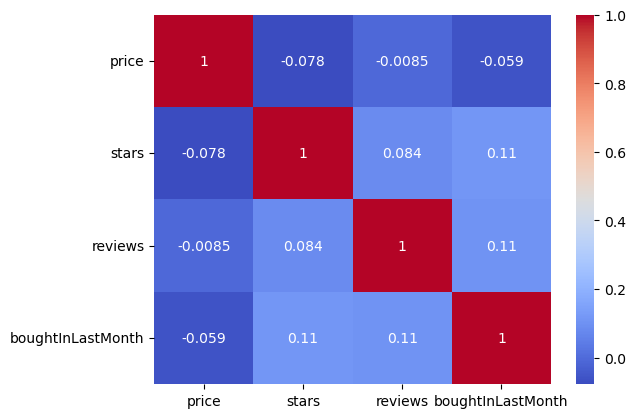

In [39]:
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

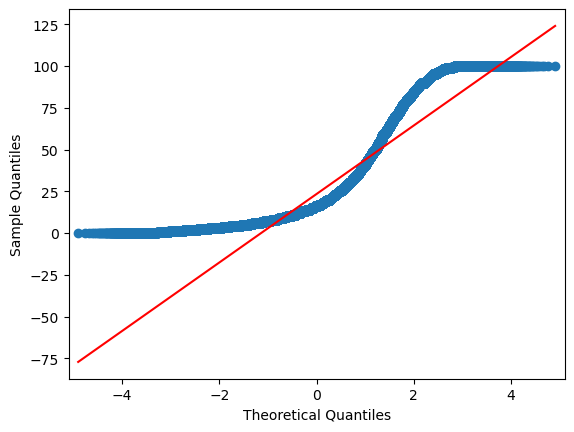

In [44]:
import statsmodels.api as sm
sm.qqplot(df_amazon_price['price'], line='s')
plt.show()

In [ ]:
# El QQ plot muestra desviaciones teniendo en cuenta la linea de normalidad (roja), con diferencias en cuantiles extremos. Esto indica que no hay una distribución normal en el precio. Además, los cuantiles superiores se aplanan alrededor de 100.